# PCB Component Placement Classification

**Author:** Mayur More · **Context:** Academic transfer-learning project with a hypothetical electronics-manufacturing scenario.

## 1. Problem

Classify annotation-centred images as acceptable placement (`good`, 0) or incorrect placement (`no_good`, 1), using an ImageNet-pretrained MobileNetV2. The task is binary classification, not component detection or a general solder-defect classifier. Balanced accuracy weights the two class recalls equally; F1 is reported for Incorrect. The selected data is nearly balanced. No real internship, client engagement, deployed inspection system or measured manufacturing benefit is claimed.

### Saved pipeline results

228 labelled V1 images; training/validation/test sizes 160/34/34. Selected validation balanced accuracy/F1: 0.7639/0.7778. Saved test balanced accuracy/F1: 0.8529/0.8571.

These are historical saved results, not a fresh reproduced training run. All six board designs appear in every split. Earlier experiments inspected test diagnostics for ten configurations; the project therefore does not establish a never-inspected confirmatory test. See [evaluation](docs/EVALUATION.md).

Workflow: annotated image → padded 2:1 crop → training-only augmentation → MobileNetV2 → sigmoid probability → four-view averaging → validation-selected threshold → known-board test evaluation.

## Dataset and setup

Dataset: [SolDef_AI by Maurizio Calabrese](https://www.kaggle.com/datasets/mauriziocalabrese/soldef-ai-pcb-dataset-for-defect-detection). Dataset paper: [Fontana et al. (2024)](https://doi.org/10.3390/jmmp8030117).

Install `requirements.txt`, place the compatible dataset archive as `archive.zip` beside this notebook, and start Jupyter from the repository root. The code reads archive members in memory. Building MobileNetV2 can download ImageNet weights; running the notebook trains a model. See [data and setup](docs/DATA_AND_SETUP.md). Raw data is not bundled.

In [17]:
from pathlib import Path, PurePosixPath
from collections import defaultdict
import io, json, warnings, zipfile, hashlib

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score

DATA = Path('archive.zip')
assert DATA.is_file(), 'Place archive.zip in the same folder and start Jupyter there.'

SEED = 42
BATCH_SIZE = 16
MAX_EPOCHS = 30
PATIENCE = 6
CROP_W, CROP_H, CROP_MARGIN = 320, 160, 0.25

tf.get_logger().setLevel('ERROR')
warnings.filterwarnings('ignore', message='.*input_shape.*is undefined or non-square.*')

def reset_seed():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

def table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |',
             '|' + '|'.join(['---'] * len(headers)) + '|']
    lines += ['| ' + ' | '.join(map(str, row)) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))

reset_seed()
print(f'TensorFlow {tf.__version__} | Keras {tf.keras.__version__} | seed {SEED}')

TensorFlow 2.21.0 | Keras 3.14.0 | seed 42


## 2. Data checks

The notebook selects labelled V1 top-view images. Each annotation provides one binary label and polygon coordinates. The polygon defines an annotation-centred crop, not an additional numerical predictor. The code checks duplicate archive member names, annotation/image correspondence, labels, RGB orientation, bounds, and exact file/pixel duplicates. These checks are part of the implementation; saved outputs are not a fresh rerun of every assertion.

In [18]:
rows, jpeg_bytes = [], {}

with zipfile.ZipFile(DATA) as archive:
    names = archive.namelist()
    assert len(names) == len(set(names)), 'Duplicate archive member names'

    raw = defaultdict(list)
    for name in names:
        if name.startswith('SolDef_AI/Dataset/') and name.lower().endswith('.jpg'):
            raw[PurePosixPath(name).name].append(name)

    for name in sorted(n for n in names if n.endswith('.json')):
        image_name = str(PurePosixPath(name).with_suffix('.jpg'))
        basename = PurePosixPath(image_name).name

        assert len(raw[basename]) == 1
        raw_name = raw[basename][0]
        board, _, view = PurePosixPath(raw_name).parts[2:5]

        if view != 'V1':
            continue

        annotation = json.loads(archive.read(name))
        labels = [shape['label'] for shape in annotation['shapes']]
        assert len(labels) == 1 and labels[0] in ['good', 'no_good']

        points = np.array(annotation['shapes'][0]['points'], dtype=np.float64)
        box = (
            float(points[:, 0].min()),
            float(points[:, 1].min()),
            float(points[:, 0].max()),
            float(points[:, 1].max())
        )

        content = archive.read(image_name)
        assert content == archive.read(raw_name)

        with Image.open(io.BytesIO(content)) as image:
            image.load()
            assert image.mode == 'RGB'
            assert image.getexif().get(274, 1) == 1
            assert image.size == (annotation['imageWidth'], annotation['imageHeight'])
            assert 0 <= box[0] < box[2] <= image.width
            assert 0 <= box[1] < box[3] <= image.height

            pixel_hash = hashlib.sha256(
                f'{image.mode}:{image.width}:{image.height}:'.encode() + image.tobytes()
            ).hexdigest()
            dimensions = image.size

        sample = PurePosixPath(image_name).stem
        jpeg_bytes[sample] = content
        rows.append({
            'id': sample,
            'board': board,
            'target': int(labels[0] == 'no_good'),
            'dimensions': dimensions,
            'box': box,
            'file_hash': hashlib.sha256(content).hexdigest(),
            'pixel_hash': pixel_hash
        })

assert len(rows) == len(jpeg_bytes) == 228
file_duplicate_count = len(rows) - len({r['file_hash'] for r in rows})
pixel_duplicate_count = len(rows) - len({r['pixel_hash'] for r in rows})
assert file_duplicate_count == pixel_duplicate_count == 0

table(['Data quality check', 'Result'], [
    ['Valid top-view photographs', len(rows)],
    ['Source dimensions', str(sorted({r['dimensions'] for r in rows}))],
])


| Data quality check | Result |
|---|---|
| Valid top-view photographs | 228 |
| Source dimensions | [(2560, 1440)] |

## 3. Exploration and metrics

The selected pool contains 228 labelled top-view images from CS1–CS6: 112 Good and 116 Incorrect. Figure 1 shows board/class counts and annotation-box geometry; Figure 2 shows source-image examples.

Balanced accuracy is the mean of Good and Incorrect recall. F1 measures precision/recall balance for Incorrect. All six boards appear in training, validation and test. Results concern unseen images of known designs, not unseen-board generalization.

| Board | Good | Incorrect |
|---|---|---|
| CS1 | 8 | 22 |
| CS2 | 20 | 20 |
| CS3 | 15 | 15 |
| CS4 | 18 | 22 |
| CS5 | 19 | 21 |
| CS6 | 32 | 16 |

| Full pool | Good | Incorrect |
|---|---|---|
| 228 | 112 | 116 |

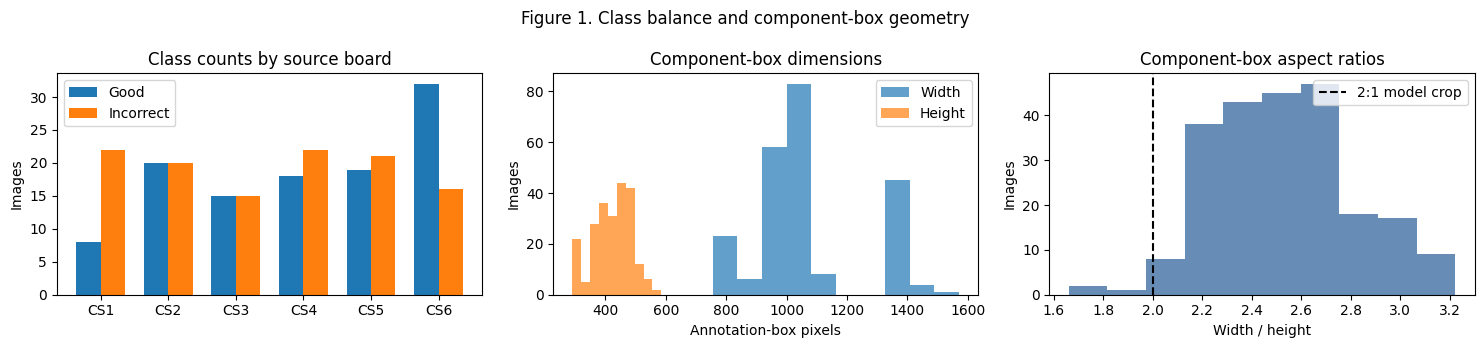

In [19]:
boards = sorted({r['board'] for r in rows})
board_counts = [[board,
    sum(r['board'] == board and r['target'] == 0 for r in rows),
    sum(r['board'] == board and r['target'] == 1 for r in rows)] for board in boards]
table(['Board', 'Good', 'Incorrect'], board_counts)
table(['Full pool', 'Good', 'Incorrect'], [[len(rows),
    sum(r['target'] == 0 for r in rows), sum(r['target'] == 1 for r in rows)]])

box_widths = np.array([r['box'][2] - r['box'][0] for r in rows])
box_heights = np.array([r['box'][3] - r['box'][1] for r in rows])
box_aspect_ratios = box_widths / box_heights

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
positions = np.arange(len(board_counts))
axes[0].bar(positions-.18, [r[1] for r in board_counts], .36, label='Good')
axes[0].bar(positions+.18, [r[2] for r in board_counts], .36, label='Incorrect')
axes[0].set(xticks=positions, xticklabels=boards, ylabel='Images',
            title='Class counts by source board')
axes[0].legend()

axes[1].hist(box_widths, bins=10, alpha=.70, label='Width')
axes[1].hist(box_heights, bins=10, alpha=.70, label='Height')
axes[1].set(xlabel='Annotation-box pixels', ylabel='Images',
            title='Component-box dimensions')
axes[1].legend()

axes[2].hist(box_aspect_ratios, bins=10, color='#4C78A8', alpha=.85)
axes[2].axvline(2.0, linestyle='--', color='black', label='2:1 model crop')
axes[2].set(xlabel='Width / height', ylabel='Images',
            title='Component-box aspect ratios')
axes[2].legend()

fig.suptitle('Figure 1. Class balance and component-box geometry')
fig.tight_layout(); plt.show()


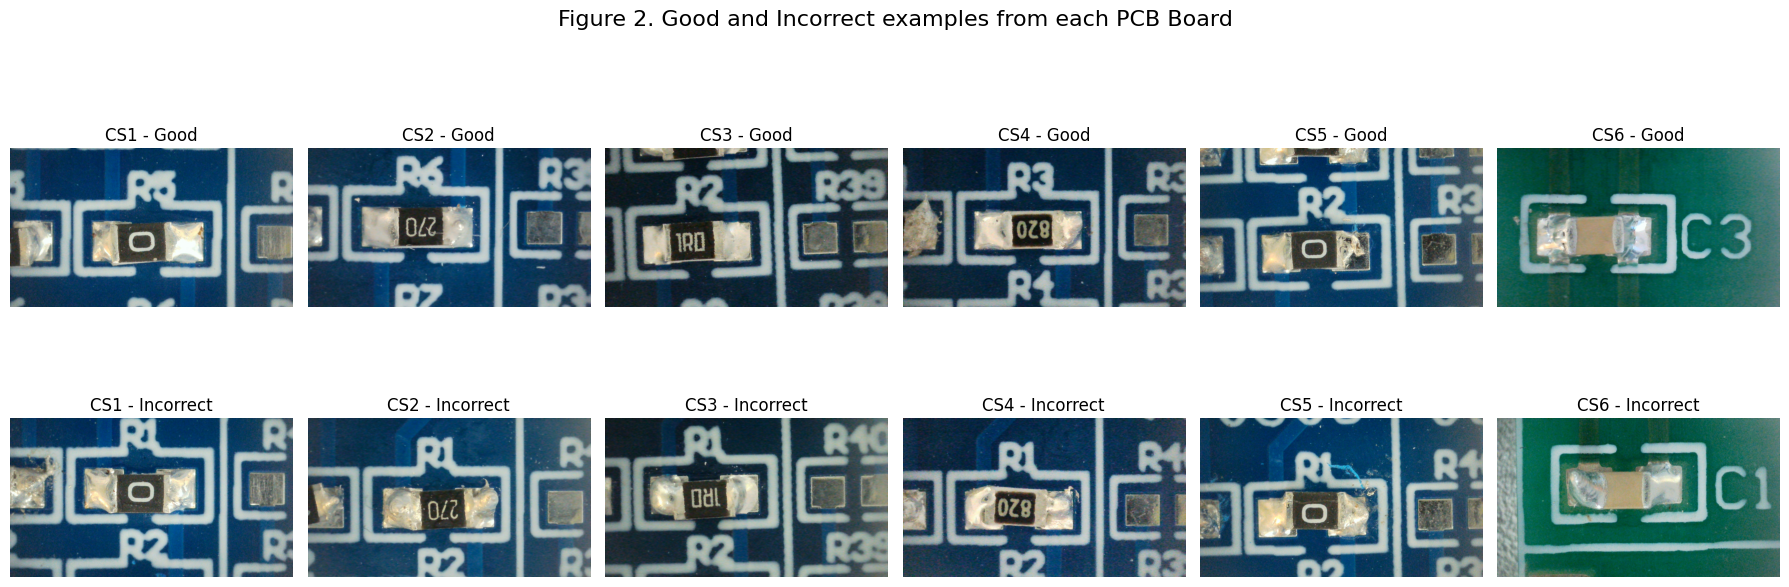

In [20]:
boards = sorted({r['board'] for r in rows})

fig, axes = plt.subplots(2, len(boards), figsize=(18, 7))

for col, board in enumerate(boards):

    good_sample = next(
        r for r in rows
        if r['board'] == board and r['target'] == 0
    )

    incorrect_sample = next(
        r for r in rows
        if r['board'] == board and r['target'] == 1
    )

    # Good image
    with Image.open(io.BytesIO(jpeg_bytes[good_sample['id']])) as image:
        axes[0, col].imshow(image.convert('RGB'))

    axes[0, col].set_title(f'{board} - Good')
    axes[0, col].axis('off')

    # Incorrect image
    with Image.open(io.BytesIO(jpeg_bytes[incorrect_sample['id']])) as image:
        axes[1, col].imshow(image.convert('RGB'))

    axes[1, col].set_title(f'{board} - Incorrect')
    axes[1, col].axis('off')

fig.suptitle('Figure 2. Good and Incorrect examples from each PCB Board', fontsize=16)

plt.tight_layout()
plt.show()

## 4. Training, validation and test partitions

Seed 42 produces stratified image-level partitions: training 160 (79 Good, 81 Incorrect), validation 34 (16 Good, 18 Incorrect), test 34 (17 Good, 17 Incorrect). The current code uses validation for model diagnostics and threshold selection, then reports the selected model on the test partition.

Historical research also evaluated ten configurations on this same test partition. The archived record describes those scores as diagnostic and says validation determined selection. This does not establish a never-inspected test across the project history.

In [21]:
all_targets = np.array([row['target'] for row in rows], dtype=np.float32)
all_indices = np.arange(len(rows))

train_idx, remainder_idx = train_test_split(
    all_indices, train_size=160, test_size=68,
    random_state=SEED, stratify=all_targets)
validation_idx, test_idx = train_test_split(
    remainder_idx, train_size=34, test_size=34,
    random_state=SEED, stratify=all_targets[remainder_idx])

assert [len(train_idx), len(validation_idx), len(test_idx)] == [160, 34, 34]
assert not (set(train_idx) & set(validation_idx)
            or set(train_idx) & set(test_idx)
            or set(validation_idx) & set(test_idx))

train_rows = [rows[i] for i in train_idx]
validation_rows = [rows[i] for i in validation_idx]
test_rows = [rows[i] for i in test_idx]
y_train = all_targets[train_idx]
y_validation = all_targets[validation_idx]
y_test = all_targets[test_idx]

split_rows = []
for name, indices in [('Train', train_idx),
                      ('Validation', validation_idx),
                      ('Test', test_idx)]:
    target = all_targets[indices]
    represented = sorted({rows[i]['board'] for i in indices})
    split_rows.append([
        name, len(indices), f'{len(indices)/len(rows):.2%}',
        int((target == 0).sum()), int((target == 1).sum()),
        ', '.join(represented)
    ])

table(['Split', 'Images', 'Share', 'Good', 'Incorrect', 'Boards'], split_rows)

| Split | Images | Share | Good | Incorrect | Boards |
|---|---|---|---|---|---|
| Train | 160 | 70.18% | 79 | 81 | CS1, CS2, CS3, CS4, CS5, CS6 |
| Validation | 34 | 14.91% | 16 | 18 | CS1, CS2, CS3, CS4, CS5, CS6 |
| Test | 34 | 14.91% | 17 | 17 | CS1, CS2, CS3, CS4, CS5, CS6 |

## 5. Preprocessing and prediction views

Annotation bounds define a component-centred 2:1 crop with 25% margins on each side, adjusted to image boundaries and resized to 320 pixels wide by 160 high. The classifier requires localization geometry at inference; it does not locate the component itself.

Training-only augmentation applies horizontal/vertical flips, brightness and contrast variation. Validation/test do not use random augmentation. Inference averages four deterministic views: original, horizontal flip, vertical flip and both flips. This is test-time augmentation, not four separately trained models. Figures 3 and 4 illustrate crops and views.

In [22]:
def crop_image(row):
    x0, y0, x1, y1 = row['box']
    component_w, component_h = x1 - x0, y1 - y0
    centre_x, centre_y = (x0 + x1) / 2, (y0 + y1) / 2

    crop_w = component_w * (1 + 2 * CROP_MARGIN)
    crop_h = crop_w * CROP_H / CROP_W
    required_h = component_h * (1 + 2 * CROP_MARGIN)
    if crop_h < required_h:
        crop_h = required_h
        crop_w = crop_h * CROP_W / CROP_H

    with Image.open(io.BytesIO(jpeg_bytes[row['id']])) as source:
        source = source.convert('RGB')
        image_w, image_h = source.size
        crop_w, crop_h = min(crop_w, image_w), min(crop_h, image_h)
        left = min(max(0., centre_x - crop_w / 2), image_w - crop_w)
        top = min(max(0., centre_y - crop_h / 2), image_h - crop_h)
        crop = source.crop((round(left), round(top),
                            round(left + crop_w), round(top + crop_h)))

    crop = crop.resize((CROP_W, CROP_H), Image.Resampling.LANCZOS)
    return np.asarray(crop, dtype=np.float32)

def prediction_views(images):
    return [images,
            images[:, :, ::-1],
            images[:, ::-1, :],
            images[:, ::-1, ::-1]]

def training_augmentation():
    return tf.keras.Sequential([
        tf.keras.layers.RandomFlip('horizontal_and_vertical'),
        tf.keras.layers.RandomBrightness(0.1),
        tf.keras.layers.RandomContrast(0.1),
    ], name='training_augmentation')

train_images = np.stack([crop_image(row) for row in train_rows])
validation_images = np.stack([crop_image(row) for row in validation_rows])
test_images = np.stack([crop_image(row) for row in test_rows])

assert train_images.shape == (160, CROP_H, CROP_W, 3)
assert validation_images.shape == test_images.shape == (34, CROP_H, CROP_W, 3)

print('Image arrays:', train_images.shape, validation_images.shape, test_images.shape)


Image arrays: (160, 160, 320, 3) (34, 160, 320, 3) (34, 160, 320, 3)


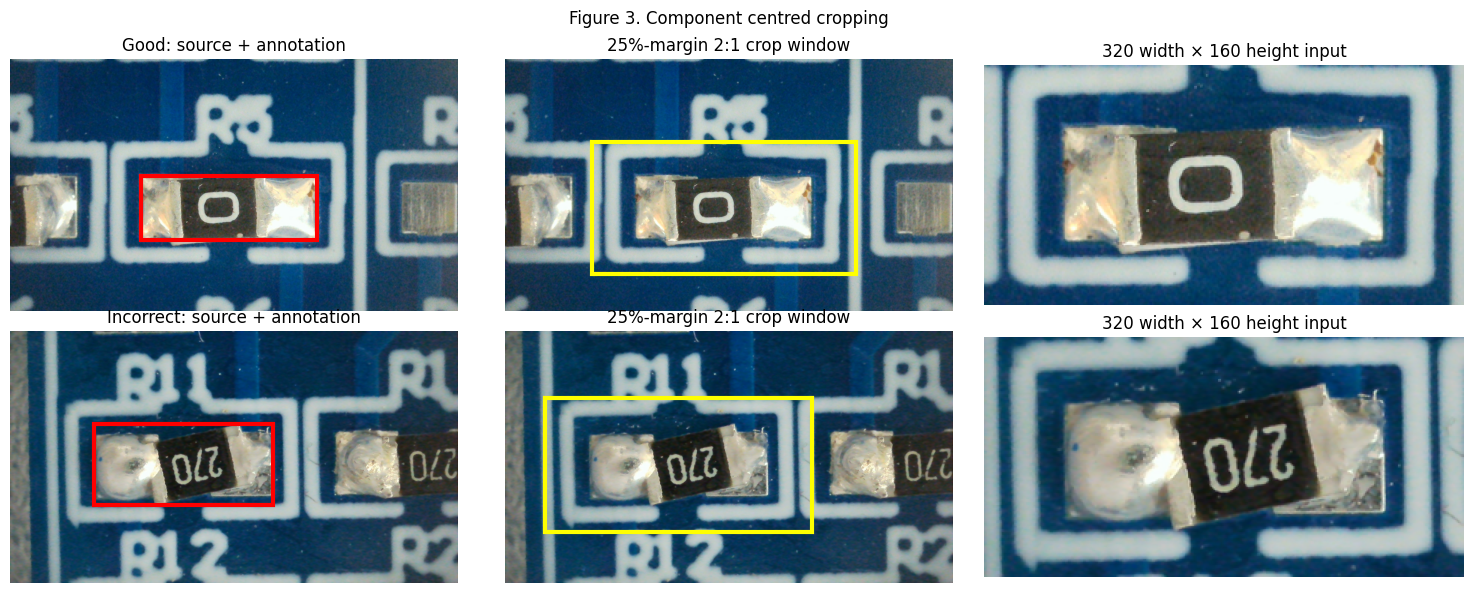

In [23]:
from matplotlib.patches import Rectangle

def display_crop_bounds(row):
    x0, y0, x1, y1 = row['box']
    component_w, component_h = x1 - x0, y1 - y0
    centre_x, centre_y = (x0 + x1) / 2, (y0 + y1) / 2

    crop_w = component_w * (1 + 2 * CROP_MARGIN)
    crop_h = crop_w * CROP_H / CROP_W
    required_h = component_h * (1 + 2 * CROP_MARGIN)
    if crop_h < required_h:
        crop_h = required_h
        crop_w = crop_h * CROP_W / CROP_H

    image_w, image_h = row['dimensions']
    crop_w, crop_h = min(crop_w, image_w), min(crop_h, image_h)
    left = min(max(0., centre_x - crop_w / 2), image_w - crop_w)
    top = min(max(0., centre_y - crop_h / 2), image_h - crop_h)
    return left, top, crop_w, crop_h

preprocessing_examples = [
    ('Good', next(row for row in train_rows if row['target'] == 0)),
    ('Incorrect', next(row for row in train_rows if row['target'] == 1)),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for row_number, (label, row) in enumerate(preprocessing_examples):
    with Image.open(io.BytesIO(jpeg_bytes[row['id']])) as source:
        full_image = np.asarray(source.convert('RGB'))

    x0, y0, x1, y1 = row['box']
    left, top, width, height = display_crop_bounds(row)

    axes[row_number, 0].imshow(full_image)
    axes[row_number, 0].add_patch(Rectangle(
        (x0, y0), x1-x0, y1-y0, fill=False,
        edgecolor='red', linewidth=3))
    axes[row_number, 0].set_title(f'{label}: source + annotation')

    axes[row_number, 1].imshow(full_image)
    axes[row_number, 1].add_patch(Rectangle(
        (left, top), width, height, fill=False,
        edgecolor='yellow', linewidth=3))
    axes[row_number, 1].set_title('25%-margin 2:1 crop window')

    axes[row_number, 2].imshow(crop_image(row).astype(np.uint8))
    axes[row_number, 2].set_title('320 width × 160 height input')

    for axis in axes[row_number]:
        axis.axis('off')

fig.suptitle('Figure 3. Component centred cropping')
fig.tight_layout(); plt.show()


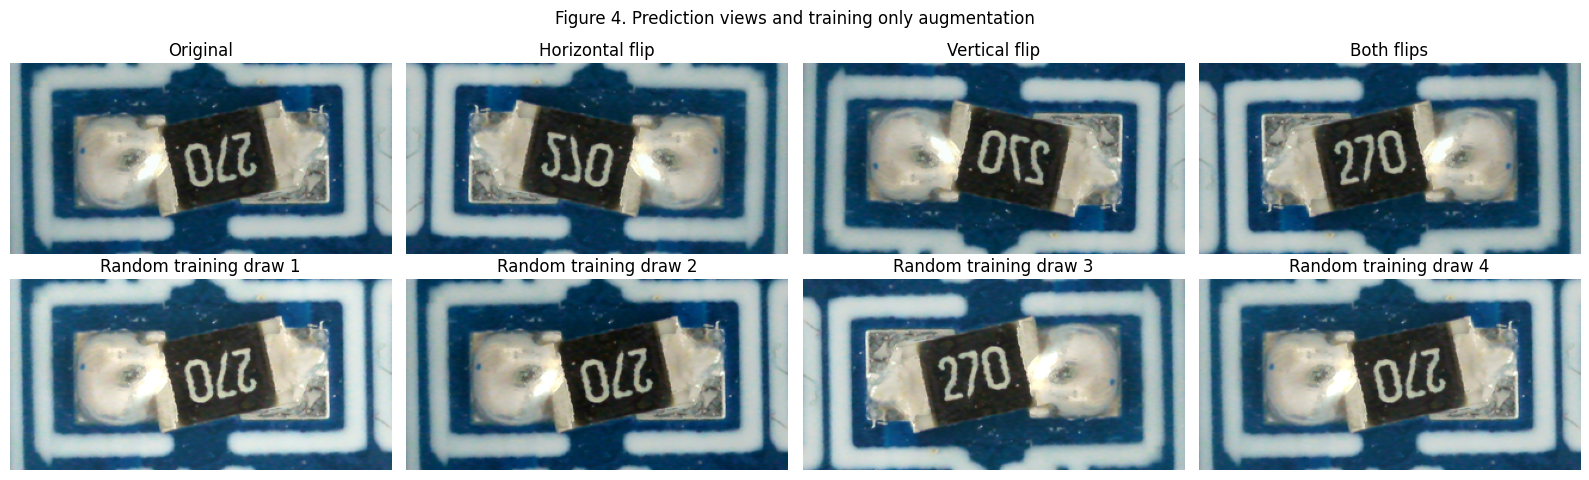

In [24]:
reset_seed()
augmenter = training_augmentation()
random_views = augmenter(np.repeat(train_images[:1], 4, axis=0), training=True).numpy()

fig, axes = plt.subplots(2, 4, figsize=(16, 5))
for ax, view, title in zip(
        axes[0], prediction_views(train_images[:1]),
        ['Original', 'Horizontal flip', 'Vertical flip', 'Both flips']):
    ax.imshow(view[0].astype(np.uint8)); ax.set_title(title); ax.axis('off')
for number, (ax, view) in enumerate(zip(axes[1], random_views), start=1):
    ax.imshow(np.clip(view, 0, 255).astype(np.uint8))
    ax.set_title(f'Random training draw {number}'); ax.axis('off')
fig.suptitle('Figure 4. Prediction views and training only augmentation')
fig.tight_layout(); plt.show()


## 6. Selected Neural Network Architecture - MobileNetV2 (after multiple hyperparameter grid search, freezing and unfreezing the pretrained layers and weights)

My final model is classifier uses **MobileNetV2 pretrained on ImageNet** and used transfer learning. The orignal ImageNet classification head is replaced with a binary classification head.

### Architecture

**Input tensor (160 height × 320 width × 3 channels)** 
**→ training augmentation**   
**→ rescaling to MobileNetV2 input range [-1, 1]**   
**→ ImageNet-pretrained MobileNetV2 convolutional**   
**→ global average pooling (built into the backbone configuration)**   
**→ Dropout (0.30)**   
**→ Dense(1, sigmoid)**   
**→ probability of Incorrect placement** 

Here the fine tuning begins at **`block_14_expand`**. the previous backbone layers remain frozen, while later layers can adapt to PCB specific appearance. **Batch Normalisation layers remain frozen** due to the small training set.

### Selected G19 settings

- Model tensor: **160 height × 320 width × 3 channels**
- Pretrained backbone: **MobileNetV2 / ImageNet**
- Fine-tuning start: **`block_14_expand`**
- Dropout: **0.30**
- Classifier L2 regularisation: **0**
- Optimizer: **Adam**
- Learning rate: **0.00005**
- Loss: **Binary cross-entropy**
- Output: **single sigmoid probability**
- Total parameters: approximately **2.26 million**
- Trainable parameters: approximately **1.51 million**

My Final architecture is compact transfer learning model, still allowing the upper MobileNetV2 layers to adapt to the solder placement classification task. and during validation and test prediction, it disables the random augmentation layer and the backbone runs with `training=False`, so Batch Normalisation statistics remain fixed.

In [25]:
def build_g19_model():
    backbone = tf.keras.applications.MobileNetV2(
        include_top=False,
        weights='imagenet',
        input_shape=(CROP_H, CROP_W, 3),
        pooling='avg')

    trainable = False
    for layer in backbone.layers:
        if layer.name == 'block_14_expand':
            trainable = True
        layer.trainable = trainable and not isinstance(
            layer, tf.keras.layers.BatchNormalization)

    inputs = tf.keras.Input((CROP_H, CROP_W, 3), name='component_crop')
    x = training_augmentation()(inputs)
    x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1)(x)
    x = backbone(x, training=False)
    x = tf.keras.layers.Dropout(0.30)(x)
    outputs = tf.keras.layers.Dense(1, activation='sigmoid')(x)

    model = tf.keras.Model(inputs, outputs, name='mobilenetv2_g19')
    model.compile(
        optimizer=tf.keras.optimizers.Adam(5e-5),
        loss='binary_crossentropy')
    return model

def predict_with_flips(model, images):
    views = np.ascontiguousarray(np.concatenate(prediction_views(images)))
    scores = model.predict(views, batch_size=32, verbose=0)
    return scores.reshape(4, len(images)).mean(axis=0)

def calculate_metrics(y_true, scores, threshold):
    predictions = (np.asarray(scores) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]).ravel()
    return {
        'balanced_accuracy': balanced_accuracy_score(y_true, predictions),
        'f1': f1_score(y_true, predictions, zero_division=0),
        'tn': int(tn), 'fp': int(fp),
        'fn': int(fn), 'tp': int(tp),
    }

reset_seed()
model = build_g19_model()
trainable_parameters = sum(int(np.prod(weight.shape))
                           for weight in model.trainable_weights)
table(['Selected-model property', 'Value'], [
    ['Configuration', 'G19'],
    ['Input', f'{CROP_H} × {CROP_W} × 3'],
    ['Backbone', 'MobileNetV2 with ImageNet weights'],
    ['Fine-tuning start', 'block_14_expand'],
    ['Learning rate / dropout', '0.00005 / 0.30'],
    ['Classifier L2', '0'],
    ['Total parameters', f'{model.count_params():,}'],
    ['Trainable parameters', f'{trainable_parameters:,}'],
])

| Selected-model property | Value |
|---|---|
| Configuration | G19 |
| Input | 160 × 320 × 3 |
| Backbone | MobileNetV2 with ImageNet weights |
| Fine-tuning start | block_14_expand |
| Learning rate / dropout | 0.00005 / 0.30 |
| Classifier L2 | 0 |
| Total parameters | 2,259,265 |
| Trainable parameters | 1,512,001 |

## 7. Experimental Validation result Comparison of all Configuration and Final Model Selection

I had done a controlled grid search evaluating **24 MobileNetV2 configurations** using the same fixed training and validation partition. In that experiments the varied four major training/model where decided and also while keeping the image preparation and evaluation parameters constant:

- learning rate: `0.00005`, `0.0001`, `0.0002`;
- dropout: `0.20`, `0.30`;
- fine tuning start: `block_13_expand`, `block_14_expand`;
- classifier L2 regularisation: `0`, `0.0001`.

after that the sorting configurations was done using **validation Balanced Accuracy at threshold 0.50**, with validation F1 used as the secondary comparison metrics and the archive describes validation as the selection basis. Separate historical test diagnostics for ten configurations are disclosed in docs/EVALUATION.md.

The top 10 configurations are below and the below Figure 5 displays all 24 saved validation scores and makes the effect of fine tuning visually.

| Rank | Config | Learning Rate | Dropout | Fine-tuning Start | L2 | Best Epoch | Validation Balanced Accuracy | Validation F1 |
|---:|---|---:|---:|---|---:|---:|---:|---:|
| 1 | G19 | 0.00005 | 0.30 | `block_14_expand` | 0 | 3 | 0.7639 | 0.7778 |
| 2 | G22 | 0.00005 | 0.30 | `block_14_expand` | 0.0001 | 3 | 0.7639 | 0.7778 |
| 3 | G07 | 0.00005 | 0.20 | `block_14_expand` | 0 | 3 | 0.7326 | 0.7568 |
| 4 | G10 | 0.00005 | 0.20 | `block_14_expand` | 0.0001 | 3 | 0.7326 | 0.7568 |
| 5 | G11 | 0.00010 | 0.20 | `block_14_expand` | 0.0001 | 8 | 0.7153 | 0.6667 |
| 6 | G01 | 0.00005 | 0.20 | `block_13_expand` | 0 | 3 | 0.6701 | 0.7179 |
| 7 | G04 | 0.00005 | 0.20 | `block_13_expand` | 0.0001 | 3 | 0.6701 | 0.7179 |
| 8 | G08 | 0.00010 | 0.20 | `block_14_expand` | 0 | 3 | 0.6667 | 0.7317 |
| 9 | G02 | 0.00010 | 0.20 | `block_13_expand` | 0 | 14 | 0.6493 | 0.6471 |
| 10 | G13 | 0.00005 | 0.30 | `block_13_expand` | 0 | 7 | 0.6458 | 0.6667 |

**G19 and G22 models tie on primary validation metrics. G19 is selected finally because it achieves the same validation performance without using classifier L2 regularisation**

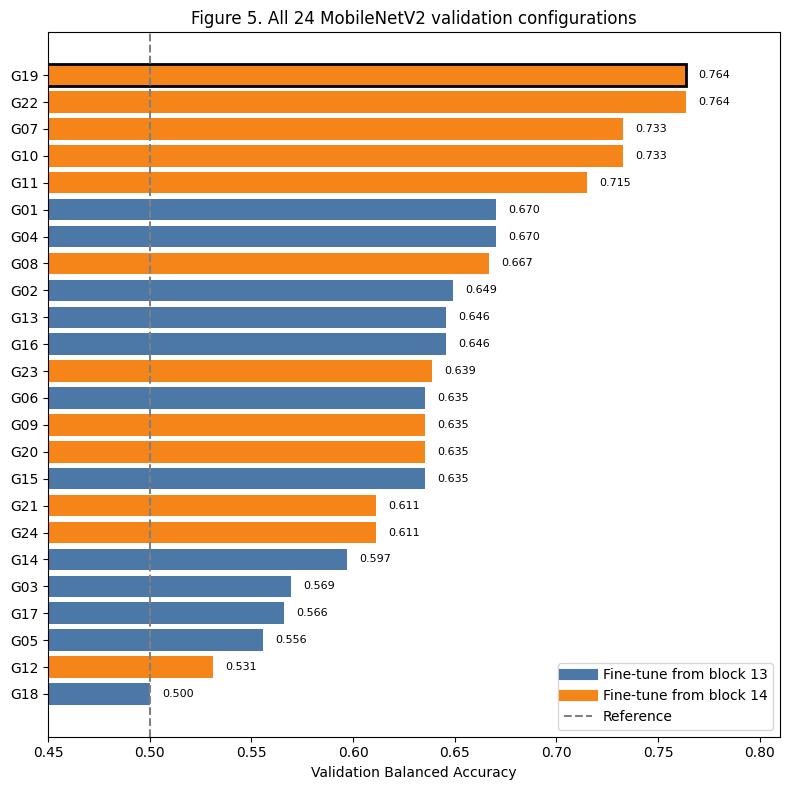

In [26]:
grid_plot_rows = [
    ('G19', 5e-5, .30, 'block_14_expand', 0.0,    .7638888889),
    ('G22', 5e-5, .30, 'block_14_expand', 1e-4,   .7638888889),
    ('G07', 5e-5, .20, 'block_14_expand', 0.0,    .7326388889),
    ('G10', 5e-5, .20, 'block_14_expand', 1e-4,   .7326388889),
    ('G11', 1e-4, .20, 'block_14_expand', 1e-4,   .7152777778),
    ('G01', 5e-5, .20, 'block_13_expand', 0.0,    .6701388889),
    ('G04', 5e-5, .20, 'block_13_expand', 1e-4,   .6701388889),
    ('G08', 1e-4, .20, 'block_14_expand', 0.0,    .6666666667),
    ('G02', 1e-4, .20, 'block_13_expand', 0.0,    .6493055556),
    ('G13', 5e-5, .30, 'block_13_expand', 0.0,    .6458333333),
    ('G16', 5e-5, .30, 'block_13_expand', 1e-4,   .6458333333),
    ('G23', 1e-4, .30, 'block_14_expand', 1e-4,   .6388888889),
    ('G06', 2e-4, .20, 'block_13_expand', 1e-4,   .6354166667),
    ('G09', 2e-4, .20, 'block_14_expand', 0.0,    .6354166667),
    ('G20', 1e-4, .30, 'block_14_expand', 0.0,    .6354166667),
    ('G15', 2e-4, .30, 'block_13_expand', 0.0,    .6354166667),
    ('G21', 2e-4, .30, 'block_14_expand', 0.0,    .6111111111),
    ('G24', 2e-4, .30, 'block_14_expand', 1e-4,   .6111111111),
    ('G14', 1e-4, .30, 'block_13_expand', 0.0,    .5972222222),
    ('G03', 2e-4, .20, 'block_13_expand', 0.0,    .5694444444),
    ('G17', 1e-4, .30, 'block_13_expand', 1e-4,   .5659722222),
    ('G05', 1e-4, .20, 'block_13_expand', 1e-4,   .5555555556),
    ('G12', 2e-4, .20, 'block_14_expand', 1e-4,   .5312500000),
    ('G18', 2e-4, .30, 'block_13_expand', 1e-4,   .5000000000),
]

plot_rows = list(reversed(grid_plot_rows))
labels = [row[0] for row in plot_rows]
scores = [row[5] for row in plot_rows]
colours = ['#F58518' if row[3] == 'block_14_expand' else '#4C78A8'
           for row in plot_rows]

fig, ax = plt.subplots(figsize=(8, 8))
bars = ax.barh(labels, scores, color=colours)
for bar, row in zip(bars, plot_rows):
    if row[0] == 'G19':
        bar.set_edgecolor('black'); bar.set_linewidth(2)
    ax.text(row[5] + .006, bar.get_y() + bar.get_height()/2,
            f'{row[5]:.3f}', va='center', fontsize=8)

ax.axvline(.5, linestyle='--', color='grey', label='Constant-class reference')
ax.set(xlim=(.45, .81), xlabel='Validation Balanced Accuracy',
       title='Figure 5. All 24 MobileNetV2 validation configurations')
ax.legend(handles=[
    plt.Line2D([0], [0], color='#4C78A8', lw=8, label='Fine-tune from block 13'),
    plt.Line2D([0], [0], color='#F58518', lw=8, label='Fine-tune from block 14'),
    plt.Line2D([0], [0], color='grey', linestyle='--', label='Reference'),
], loc='lower right')
fig.tight_layout(); plt.show()


## 8. Training and threshold selection

G19 is trained on 160 images. Code sets a maximum of **30 epochs** and early-stopping **patience of six epochs**, monitoring validation binary cross-entropy and restoring the best weights. Six is the patience, not the maximum epoch count.

The decision threshold is chosen from validation predictions: consider thresholds within 0.01 of the maximum validation balanced accuracy and use their median. Saved results give best epoch 3, threshold 0.50, validation balanced accuracy 0.7639 and Incorrect F1 0.7778. Figure 6 displays training and threshold diagnostics. The current training/threshold code does not consume test labels; historical test exposure is documented separately.

| Validation result | Value |
|---|---|
| Selected model | MobileNetV2 G19 |
| Best epoch | 3 |
| Decision threshold | 0.50 |
| Balanced Accuracy | 0.7639 |
| F1 | 0.7778 |

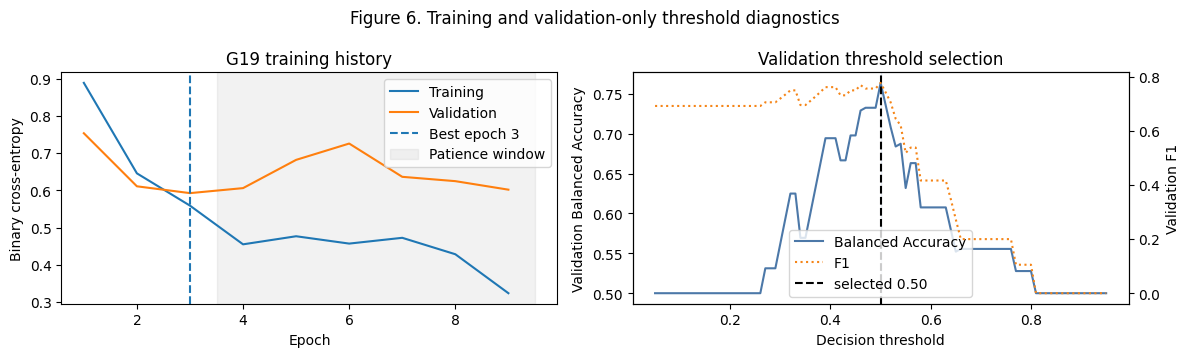

In [27]:
reset_seed()
model = build_g19_model()
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=PATIENCE, restore_best_weights=True)

history = model.fit(
    train_images, y_train,
    validation_data=(validation_images, y_validation),
    batch_size=BATCH_SIZE,
    epochs=MAX_EPOCHS,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=0)

best_epoch = int(np.argmin(history.history['val_loss'])) + 1
validation_scores = predict_with_flips(model, validation_images)

threshold_grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
balanced_accuracy_by_threshold = np.array([
    balanced_accuracy_score(
        y_validation, (validation_scores >= threshold).astype(int))
    for threshold in threshold_grid
])
f1_by_threshold = np.array([
    f1_score(
        y_validation, (validation_scores >= threshold).astype(int),
        zero_division=0)
    for threshold in threshold_grid
])
plateau = threshold_grid[
    balanced_accuracy_by_threshold >= balanced_accuracy_by_threshold.max() - 0.01]
selected_threshold = round(float(np.median(plateau)), 2)
validation_result = calculate_metrics(
    y_validation, validation_scores, selected_threshold)

table(['Validation result', 'Value'], [
    ['Selected model', 'MobileNetV2 G19'],
    ['Best epoch', best_epoch],
    ['Decision threshold', f'{selected_threshold:.2f}'],
    ['Balanced Accuracy', f"{validation_result['balanced_accuracy']:.4f}"],
    ['F1', f"{validation_result['f1']:.4f}"],
])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
epochs = np.arange(1, len(history.history['loss']) + 1)
axes[0].plot(epochs, history.history['loss'], label='Training')
axes[0].plot(epochs, history.history['val_loss'], label='Validation')
axes[0].axvline(best_epoch, linestyle='--', label=f'Best epoch {best_epoch}')
if epochs[-1] > best_epoch:
    axes[0].axvspan(best_epoch + .5, epochs[-1] + .5, alpha=.10,
                    color='grey', label='Patience window')
axes[0].set(xlabel='Epoch', ylabel='Binary cross-entropy',
            title='G19 training history')
axes[0].legend()

ba_axis = axes[1]
f1_axis = ba_axis.twinx()
ba_line, = ba_axis.plot(
    threshold_grid, balanced_accuracy_by_threshold,
    color='#4C78A8', label='Balanced Accuracy')
f1_line, = f1_axis.plot(
    threshold_grid, f1_by_threshold,
    color='#F58518', linestyle=':', label='F1')
ba_axis.axvspan(plateau.min(), plateau.max(), alpha=.15,
                color='#4C78A8', label='within 0.01 of best BA')
selected_line = ba_axis.axvline(
    selected_threshold, linestyle='--', color='black',
    label=f'selected {selected_threshold:.2f}')
ba_axis.set(xlabel='Decision threshold', ylabel='Validation Balanced Accuracy',
            title='Validation threshold selection')
f1_axis.set_ylabel('Validation F1')
handles = [ba_line, f1_line, selected_line]
ba_axis.legend(handles, [h.get_label() for h in handles], loc='lower center')
fig.suptitle('Figure 6. Training and validation-only threshold diagnostics')
fig.tight_layout(); plt.show()


## 9. Saved test evaluation

The test has 34 images: 17 Good and 17 Incorrect. Saved balanced accuracy is 0.8529 and Incorrect F1 is 0.8571. The confusion matrix, rows actual Good/Incorrect and columns predicted Good/Incorrect, is `[[14, 3], [2, 15]]`.

There are 14 correctly classified Good images, 15 detected Incorrect images, three false positives and two false negatives. The 95% stratified bootstrap intervals are 0.7059–0.9706 for balanced accuracy and 0.7273–0.9697 for F1. This fixed-test bootstrap does not quantify all selection, seed or board-design uncertainty. Figures 7 and 8 show counts and scores.

| Dataset | Threshold | Balanced Accuracy | F1 |
|---|---|---|---|
| Validation | 0.50 | 0.7639 | 0.7778 |
| Final test | 0.50 | 0.8529 | 0.8571 |

| Test metric | Estimate | Stratified bootstrap 95% interval |
|---|---|---|
| Balanced Accuracy | 0.8529 | 0.7059 - 0.9706 |
| F1 | 0.8571 | 0.7273 - 0.9697 |

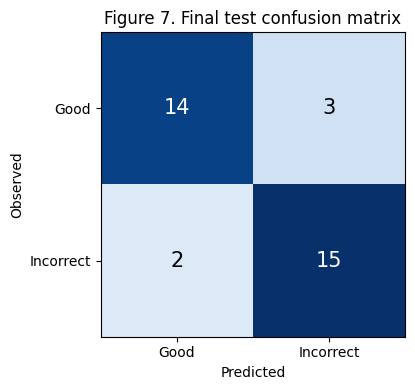

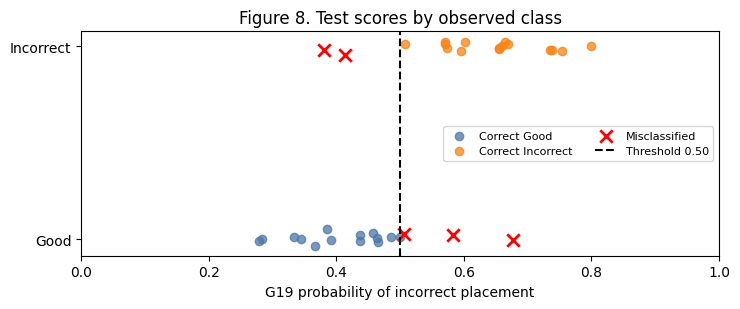

| Test-score diagnostic | Value |
|---|---|
| Minimum probability | 0.279 |
| Maximum probability | 0.799 |
| Misclassified observations | 5 |

Test BA 0.8529 | F1 0.8571


In [28]:
test_scores = predict_with_flips(model, test_images)
test_result = calculate_metrics(y_test, test_scores, selected_threshold)
test_predictions = (test_scores >= selected_threshold).astype(int)

table(['Dataset', 'Threshold', 'Balanced Accuracy', 'F1'], [
    ['Validation', f'{selected_threshold:.2f}',
     f"{validation_result['balanced_accuracy']:.4f}",
     f"{validation_result['f1']:.4f}"],
    ['Final test', f'{selected_threshold:.2f}',
     f"{test_result['balanced_accuracy']:.4f}",
     f"{test_result['f1']:.4f}"],
])

# Stratified non-parametric bootstrap: preserve the observed class counts.
bootstrap_rng = np.random.default_rng(SEED)
class_indices = [np.flatnonzero(y_test == label) for label in [0, 1]]
bootstrap_ba, bootstrap_f1 = [], []
for _ in range(2000):
    sample_indices = np.concatenate([
        bootstrap_rng.choice(indices, size=len(indices), replace=True)
        for indices in class_indices
    ])
    sampled_true = y_test[sample_indices]
    sampled_predictions = test_predictions[sample_indices]
    bootstrap_ba.append(
        balanced_accuracy_score(sampled_true, sampled_predictions))
    bootstrap_f1.append(
        f1_score(sampled_true, sampled_predictions, zero_division=0))

ba_interval = np.percentile(bootstrap_ba, [2.5, 97.5])
f1_interval = np.percentile(bootstrap_f1, [2.5, 97.5])
table(['Test metric', 'Estimate', 'Stratified bootstrap 95% interval'], [
    ['Balanced Accuracy', f"{test_result['balanced_accuracy']:.4f}",
     f'{ba_interval[0]:.4f} - {ba_interval[1]:.4f}'],
    ['F1', f"{test_result['f1']:.4f}",
     f'{f1_interval[0]:.4f} - {f1_interval[1]:.4f}'],
])

cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
fig, ax = plt.subplots(figsize=(4.8, 4.0))
ax.imshow(cm, cmap='Blues', vmin=0)
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=15,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set(xticks=[0, 1], yticks=[0, 1],
       xticklabels=['Good', 'Incorrect'], yticklabels=['Good', 'Incorrect'],
       xlabel='Predicted', ylabel='Observed',
       title='Figure 7. Final test confusion matrix')
fig.tight_layout(); plt.show()

correct = test_predictions == y_test
jitter_rng = np.random.default_rng(SEED)
jitter = jitter_rng.normal(0, .025, len(y_test))
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for label, name, colour in [(0, 'Good', '#4C78A8'),
                            (1, 'Incorrect', '#F58518')]:
    mask = (y_test == label) & correct
    ax.scatter(test_scores[mask], label + jitter[mask],
               label=f'Correct {name}', color=colour, alpha=.75)
error_mask = ~correct
ax.scatter(test_scores[error_mask], y_test[error_mask] + jitter[error_mask],
           marker='x', s=80, linewidth=2, color='red',
           label='Misclassified')
ax.axvline(selected_threshold, linestyle='--', color='black',
           label=f'Threshold {selected_threshold:.2f}')
ax.set(yticks=[0, 1], yticklabels=['Good', 'Incorrect'], xlim=(0, 1),
       xlabel='G19 probability of incorrect placement',
       title='Figure 8. Test scores by observed class')
ax.legend(ncol=2, fontsize=8)
fig.tight_layout(); plt.show()

table(['Test-score diagnostic', 'Value'], [
    ['Minimum probability', f'{test_scores.min():.3f}'],
    ['Maximum probability', f'{test_scores.max():.3f}'],
    ['Misclassified observations', int(error_mask.sum())],
])

print(f"Test BA {test_result['balanced_accuracy']:.4f} | "
      f"F1 {test_result['f1']:.4f}")


## 10. Error analysis

The saved evaluation reports all five errors. A **false negative (FN)** is an Incorrect placement predicted Good; a **false positive (FP)** is a Good placement predicted Incorrect. The practical cost of these errors is not measured here. Saved scores place the errors within 0.177 probability points of the threshold; score proximity is not a calibration guarantee.

| Image ID | Board | Observed | Predicted | Score | Distance from threshold |
|---|---|---|---|---|---|
| WIN_20220329_15_18_00_Pro | CS2 | Incorrect | Good | 0.413 | 0.087 |
| WIN_20220329_16_18_30_Pro | CS4 | Good | Incorrect | 0.506 | 0.006 |
| WIN_20220329_16_29_23_Pro | CS5 | Good | Incorrect | 0.583 | 0.083 |
| WIN_20220329_16_16_56_Pro | CS4 | Good | Incorrect | 0.677 | 0.177 |
| WIN_20220329_16_31_00_Pro | CS5 | Incorrect | Good | 0.380 | 0.120 |

All **5** test errors fall within **0.177** probability points of the validation-selected threshold (0.50); the saved errors are borderline rather than extreme-confidence mistakes.

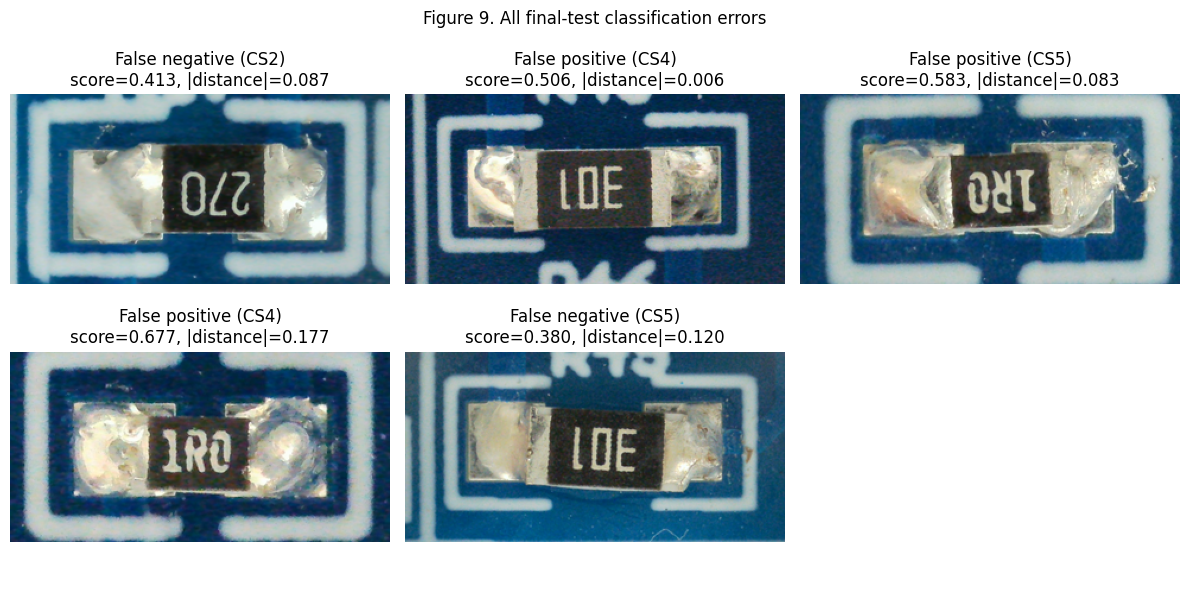

In [29]:
error_indices = np.flatnonzero(test_predictions != y_test)
class_names = {0: 'Good', 1: 'Incorrect'}
error_rows = []
for index in error_indices:
    error_rows.append([
        test_rows[index]['id'],
        test_rows[index]['board'],
        class_names[int(y_test[index])],
        class_names[int(test_predictions[index])],
        f'{test_scores[index]:.3f}',
        f'{abs(test_scores[index] - selected_threshold):.3f}',
    ])

table(
    ['Image ID', 'Board', 'Observed', 'Predicted',
     'Score', 'Distance from threshold'],
    error_rows)

if len(error_indices):
    maximum_error_distance = max(
        abs(test_scores[index] - selected_threshold)
        for index in error_indices)
    display(Markdown(
        f'All **{len(error_indices)}** test errors fall within '
        f'**{maximum_error_distance:.3f}** probability points of the '
        f'validation-selected threshold ({selected_threshold:.2f}); '
        'the saved errors are borderline rather than extreme-confidence mistakes.'))

    columns = 3
    rows_needed = int(np.ceil(len(error_indices) / columns))
    fig, axes = plt.subplots(
        rows_needed, columns, figsize=(12, 3 * rows_needed), squeeze=False)
    for axis, index in zip(axes.flat, error_indices):
        error_type = ('False negative' if y_test[index] == 1
                      else 'False positive')
        axis.imshow(test_images[index].astype(np.uint8))
        axis.set_title(
            f'{error_type} ({test_rows[index]["board"]})\n'
            f'score={test_scores[index]:.3f}, '
            f'|distance|={abs(test_scores[index]-selected_threshold):.3f}')
        axis.axis('off')
    for axis in axes.flat[len(error_indices):]:
        axis.axis('off')
    fig.suptitle('Figure 9. All final-test classification errors')
    fig.tight_layout(); plt.show()
else:
    print('No false-positive or false-negative examples.')


## 11. Conclusion and limitations

The saved G19 evaluation yields balanced accuracy 0.8529 and Incorrect F1 0.8571 on 34 images of known board designs, with two missed Incorrect placements and three false alarms. The workflow demonstrates transfer learning, annotation-centred preprocessing, validation-based configuration comparison, deterministic prediction views and error analysis.

The small image-level split shares board designs across partitions. Historical test diagnostics limit confirmatory interpretation. Cropping requires annotation geometry, training results may vary with software/hardware, and the study contains no factory deployment, unseen-board evaluation, throughput measurement or business-impact validation. It does not establish an autonomous pass/fail inspection system. See [evaluation and limitations](docs/EVALUATION.md).

## 12. References

Calabrese, M. (n.d.) *SolDef_AI PCB Dataset for Defect Detection*. Kaggle. Available at: https://www.kaggle.com/datasets/mauriziocalabrese/soldef-ai-pcb-dataset-for-defect-detection (Accessed: 18 September 2026).

Fontana, G., Calabrese, M., Agnusdei, L., Papadia, G. and Del Prete, A. (2024) ‘SolDef_AI: An Open Source PCB Dataset for Mask R-CNN Defect Detection in Soldering Processes of Electronic Components’, *Journal of Manufacturing and Materials Processing*, 8(3), article 117. Available at: https://doi.org/10.3390/jmmp8030117.